# From Cricsheet to a forecasting experiment

This notebook explains data preparation and the model foundations. See 02_research_results.ipynb for the completed experiments and docs/RESEARCH_REPORT.md for the findings and limitations.

The question is: **How quickly should we trust a change in a batter's boundary probability?** Start by distinguishing observed performance from underlying probability.

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd()
assert (ROOT / 'pipeline.py').exists(), 'Run this notebook in the cricket_form folder'
audit = json.loads((ROOT / 'reports/data_audit.json').read_text())
{k: audit[k] for k in ['first_date', 'last_date', 'raw_deliveries', 'primary_deliveries', 'boundaries']}

{'first_date': '2008-04-18',
 'last_date': '2026-05-31',
 'raw_deliveries': 295732,
 'primary_deliveries': 284465,
 'boundaries': 49905}

## 1. What is an observation?

One recorded delivery event. The primary modelling table restricts these to legal deliveries outside Super Overs. A boundary is a four or six **credited to the batter**, except where Cricsheet explicitly marks it non-boundary. Four byes are not a batter boundary. Zero-boundary deliveries are essential: they supply the denominator.

We retain the unfiltered delivery table and raw archive, allowing a sensitivity analysis that includes non-wide no-balls. We do not call the primary denominator official balls faced. Source fields: [Cricsheet JSON documentation](https://cricsheet.org/format/json/).

In [2]:
deliveries = pd.read_parquet(ROOT / 'data/processed/deliveries.parquet')
model = pd.read_parquet(ROOT / 'data/processed/model_deliveries.parquet')
assert deliveries.delivery_id.is_unique
assert model.is_legal.all() and not model.is_super_over.any()
assert (model.is_boundary == (model.batter_runs.isin([4,6]) & ~model.non_boundary)).all()
pd.Series(audit['exclusions_disjoint'], name='Excluded recorded events')

super_over_all               175
regular_wides               9871
regular_noballs_not_wide    1221
Name: Excluded recorded events, dtype: int64

In [3]:
coverage = pd.read_parquet(ROOT / 'data/processed/coverage.parquet')
coverage

,season,matches,first_date,last_date,raw_deliveries,primary_deliveries,super_over_deliveries
0,2008,58,2008-04-18,2008-06-01,13489,12950,0
1,2009,57,2009-04-18,2009-05-24,13606,13085,11
2,2010,60,2010-03-12,2010-04-25,14498,13929,9
3,2011,73,2011-04-08,2011-05-28,17013,16425,0
4,2012,74,2012-04-04,2012-05-27,17767,17208,0
5,2013,76,2013-04-03,2013-05-26,18177,17613,25
6,2014,60,2014-04-16,2014-06-01,14300,13833,12
7,2015,59,2015-04-08,2015-05-24,13652,13141,11
8,2016,60,2016-04-09,2016-05-29,14096,13618,0
9,2017,59,2017-04-05,2017-05-21,13862,13390,13


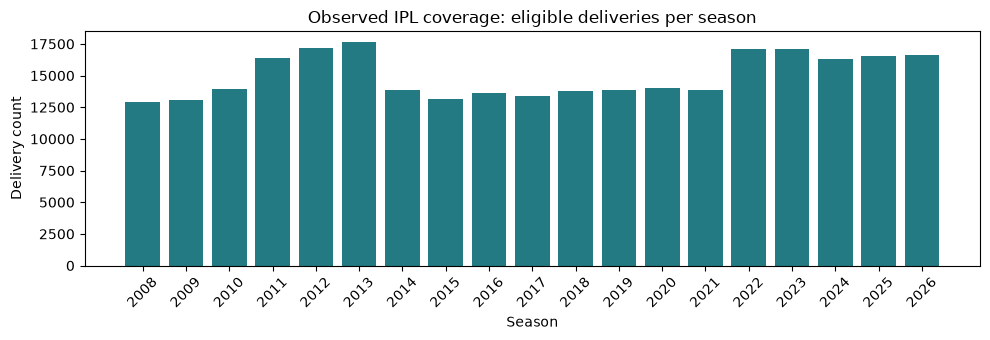

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(coverage.season.astype(str), coverage.primary_deliveries, color='#237a83')
ax.set(title='Observed IPL coverage: eligible deliveries per season', ylabel='Delivery count', xlabel='Season')
ax.tick_params(axis='x', rotation=45)
fig.tight_layout()
fig.savefig(ROOT / 'reports/coverage.png', dpi=160)
plt.show()

## 2. Aggregate with pandas

For each batter-innings, N is the number of eligible opportunities and B the number of boundaries. The observed boundary rate is B/N. Player IDs remain stable across name variations.

The example below uses development data only. These descriptive rates are observations, **not forecasts**. A high rate over ten balls is much less precise than the same rate over 500 balls.

In [5]:
development = model.loc[model.season <= 2023]
counts = development.groupby(['season', 'batter_id']).agg(
    N=('is_boundary', 'size'), B=('is_boundary', 'sum'))
counts['observed_boundary_rate'] = counts.B / counts.N
counts.head(10)

N   B  observed_boundary_rate
season batter_id                                 
2008   0184dc35   297  46                0.154882
       0264c10e    24   5                0.208333
       034b4b7d     3   1                0.333333
       0604ef16    49   4                0.081633
       0a476045   295  43                0.145763
       0aadc906    34   4                0.117647
       0c2730df    17   1                0.058824
       0d232ffd    22   3                0.136364
       0dc00542    46  13                0.282609
       0ed0cdbf     5   0                0.000000

## 3. Brown's experiment, and our adaptation

Brown used 2005 Major League Baseball hits and at-bats to predict later-season batting averages from earlier records. His comparisons included raw rates, a group mean, parametric and nonparametric empirical Bayes, James–Stein and a hierarchical Bayes approach. Some shrinkage methods substantially improved his error criterion. He used a transformed-normal framework:

$$X_i=\arcsin\sqrt{\frac{H_i+1/4}{N_i+1/2}},\qquad \operatorname{Var}(X_i)\approx\frac{1}{4N_i}.$$

He evaluated noise-corrected squared error, recognising that the validation average is itself noisy. He also tested streakiness; his appendix found evidence on roughly ten-day timescales. Therefore, investigating changing performance is not wholly absent from the original paper.

Source: [Brown (2008)](https://www.stat.berkeley.edu/users/aldous/157/Papers/brown_batting.pdf).

Our **simpler cricket adaptation** substitutes boundary opportunities and uses a beta-binomial model. This preserves the shrinkage question without reproducing every estimator or the baseball numerical results.

## 4. Why shrinkage helps

For a batter with unknown boundary probability p, propose:

$$B\mid p,N\sim\mathrm{Binomial}(N,p),\qquad p\sim\mathrm{Beta}(\alpha,\beta).$$

Then:

$$p\mid B,N\sim\mathrm{Beta}(\alpha+B,\beta+N-B),$$
$$\widehat p=\frac{\alpha+B}{\alpha+\beta+N}
=\frac{N}{N+\kappa}\frac{B}{N}+\frac{\kappa}{N+\kappa}\mu,$$

where $\mu=\alpha/(\alpha+\beta)$ and $\kappa=\alpha+\beta$.

Thus the forecast combines the player rate and the population rate. Less evidence means more weight on the population. In **empirical Bayes**, estimate alpha and beta from the training players' counts, for example by maximising the beta-binomial marginal likelihood with `scipy.optimize` and `scipy.special.betaln`. They are not arbitrary settings or estimated from validation outcomes. The likelihood integrates over each player's unknown p; do not treat the spread of raw rates as pure ability variation because it also contains sampling noise.

Here is an explicitly invented illustration, not a fitted IPL result:

In [6]:
alpha, beta = 15, 85  # hypothetical prior: mean 15%, strength 100
example = pd.DataFrame({'N':[20, 200], 'B':[6, 60]})
example['raw_rate'] = example.B / example.N
example['posterior_mean'] = (alpha + example.B) / (alpha + beta + example.N)
example

,N,B,raw_rate,posterior_mean
0,20,6,0.3,0.175
1,200,60,0.3,0.250


Both players observed 30%, but the forecasts are 17.5% and 25%. The difference comes from evidence quantity. Real alpha/beta must be learned from permitted historical data.

The binomial model assumes a stable p and conditionally independent trials. Cricket violates this idealisation through changing bowlers, pitches, tactics and correlated deliveries within innings. It is a useful first baseline, not a literal law of cricket. Beta intervals omit uncertainty in fitted hyperparameters and can be overconfident under dependence.

## 5. Keep the future out of the past

An innings' own B and N must never contribute to its pre-match forecast. We aggregate by player and date, cumulatively sum, then subtract that date's counts. All matches on the current date are excluded because start times are unavailable. `prior_N` and `prior_B` are ready for a simple expanding baseline. Missing prior rates mean no history, not zero skill.

In [7]:
innings = pd.read_parquet(ROOT / 'data/processed/batter_innings.parquet')
innings.loc[(innings.season <= 2023) & (innings.batter_id == 'ba607b88'),
    ['date','N','B','boundary_rate','prior_N','prior_B','prior_boundary_rate']].head(8)

,date,N,B,boundary_rate,prior_N,prior_B,prior_boundary_rate
12,2008-04-18,5,0,0.000000,0,0,NaN
55,2008-04-20,14,4,0.285714,5,0,0.000000
163,2008-04-26,14,1,0.071429,19,4,0.210526
224,2008-04-28,7,2,0.285714,33,5,0.151515
252,2008-04-30,1,0,0.000000,40,7,0.175000
322,2008-05-03,29,3,0.103448,41,7,0.170732
375,2008-05-05,36,5,0.138889,70,10,0.142857
513,2008-05-12,22,4,0.181818,106,15,0.141509


## 6. What we fit next

1. Early-to-late-season pooled, raw and empirical Bayes forecasts. Keep a common calendar cutoff for all players. A closer Brown replication adds his transformed-normal estimators and scoring.
2. Expanding, rolling and exponentially weighted histories, each with shrinkage. Rolling uses the last K opportunities. Exponential weighting gives older data weight $w=2^{-\Delta/h}$, with age measured in balls or days and half-life h selected on past data. Weighted counts give a practical forecast, not automatically an exact binomial posterior.
3. Compare log loss, Brier score and calibration at identical prediction times. Fit through 2023, choose on 2024, then lock the specification before scoring 2025–2026. Assess paired error differences by match/day blocks.
4. Investigate whether gains survive venue, bowler/opposition, phase and season controls. Different match conditions can mimic form. Nominal phase bands in this dataset require sensitivity checks for shortened matches.
5. Run separate end-of-season to next-season tests before producing prospective 2027 improver/rebound lists. A within-season advantage may disappear over the off-season.

**Library roles:** pandas for tables and chronological grouping; NumPy for numerical operations; SciPy for likelihood optimisation and beta distributions; scikit-learn for regularised contextual models, metrics and calibration; Matplotlib for forecasts, uncertainty and player case studies. PyArrow stores typed Parquet data efficiently.

**Interpretation:** predictive improvement supports useful recent information; it does not prove permanent skill change. A useful result may be that slow updating wins, or that differences are too uncertain to distinguish.